# Decision Tree - Assignment
## Machine Learning


## Question 1: What is a Decision Tree in Machine Learning? Explain how it works with a simple real-life example.

**Answer:** A Decision Tree is a supervised learning algorithm that works like a flowchart. It splits data by asking yes/no questions on features, until it reaches a decision.

It starts at the **Root Node**, asks questions at **Internal Nodes**, and gives the final answer at the **Leaf Node**.

**Example - Play Tennis or Not?**
- Is Weather = Sunny? -> Yes
- Is Humidity = High? -> Yes
- Decision = No, Don't Play

If Humidity = Normal, Decision = Yes, Play.

It is easy to understand, visual, and works for both Classification and Regression.

---


## Question 2: Draw and explain the main components of a Decision Tree.

**Answer:**

- **Root Node:** First node, whole dataset. Best feature to split.
- **Internal / Decision Node:** A test on a feature. Has 2 or more branches.
- **Branch:** Outcome of a test, connects nodes.
- **Leaf Node:** Final node, no further split. Gives prediction / class label.

---

## Question 3: Differentiate between a Classification Tree and a Regression Tree.

| Feature | Classification Tree | Regression Tree |
| --- | --- | --- |
| Output | Category / Class, e.g. Yes/No, Spam/Not Spam | Continuous value, e.g. Price, Marks |
| Split Criteria | Gini Impurity or Entropy / Information Gain | Mean Squared Error (MSE) or Mean Absolute Error (MAE) |
| Leaf Value | Majority class | Mean / Average of values in leaf |
| Example | Will customer buy? | What will be the house price? |

---

## Question 4: What is Gini Impurity? Explain how it helps a Decision Tree choose a split.

**Answer:** Gini Impurity measures how mixed a node is. Value is between 0 and 1.

Formula: `Gini = 1 - sum(p_i^2)` where `p_i` is probability of each class.

- **0** = Pure node, all samples same class. Best.
- **0.5** = Most impure, 50-50 mix.

Tree tries every feature and every split, calculates Gini for child nodes, and picks the split with **lowest weighted Gini**. That gives the purest children.

**Example:**
- Node with 10 Yes, 0 No = Gini = `1 - (1^2 + 0^2) = 0` - Pure.
- Node with 5 Yes, 5 No = Gini = `1 - (0.5^2 + 0.5^2) = 0.5` - Impure.

---

## Question 5: What is Entropy in a Decision Tree? Explain Information Gain.

**Answer:** Entropy also measures impurity / disorder. Range 0 to 1 for binary classification.

Formula: `Entropy = - sum(p_i * log2(p_i))`

- **0** = Pure node
- **1** = Most impure

**Information Gain = Entropy(Parent) - Weighted Average Entropy(Children)**

Tree picks the split with **highest Information Gain**, because it reduces uncertainty the most.

Gini is faster to compute, Entropy is a bit more accurate. Both give similar trees. In sklearn, default is `criterion='gini'`.

---

## Question 6: What is overfitting in a Decision Tree? Explain any three methods to reduce overfitting.

**Answer:** Overfitting is when the tree memorizes training data, including noise. It grows very deep with many leaves.

Result: Very high training accuracy, low test accuracy.

**3 Methods to reduce:**

1.  **Pruning:** Cut unnecessary branches after tree is built.
2.  **Set max_depth:** Limit depth, e.g. `max_depth=5`. Tree cannot grow too deep.
3.  **Set min_samples_split / min_samples_leaf:** Require minimum samples to split a node or to be in a leaf, e.g. `min_samples_split=10`, `min_samples_leaf=5`. Prevents tiny leaves for 1-2 samples.

Other methods: Use more training data, use Random Forest.

---

## Question 7: Explain the difference between pre-pruning and post-pruning.

| Feature | Pre-pruning | Post-pruning |
| --- | --- | --- |
| When | During tree building, stop early | After full tree is built, cut branches |
| How | Set `max_depth`, `min_samples_split`, `min_samples_leaf` | Grow full tree, then remove branches that do not improve validation accuracy |
| Speed | Faster, less memory | Slower, needs extra validation |
| Risk | May stop too early (underfitting) | More accurate, but more time |

---

## Question 8: Write a Python program using scikit-learn to create and train a DecisionTreeClassifier.

Accuracy: 1.0
Prediction for new sample: [0]
Class name: setosa


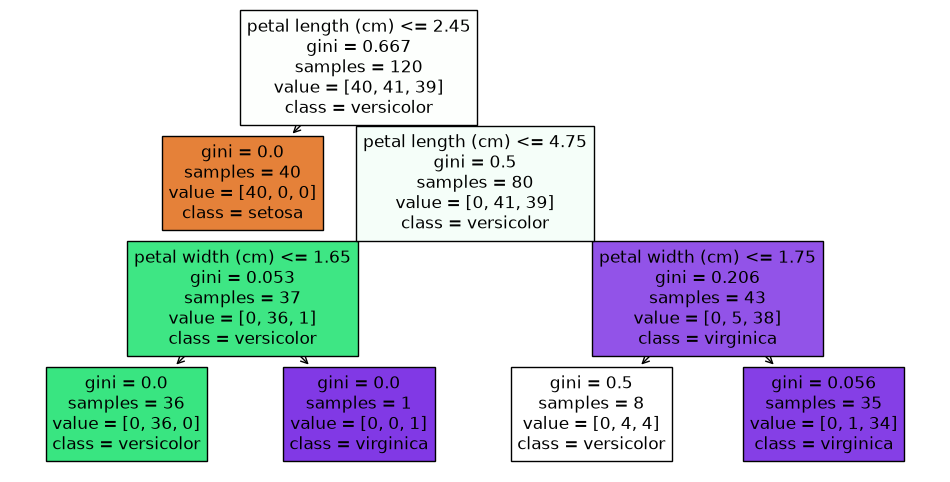

In [11]:
# **python**
# Decision Tree Classifier using sklearn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
# 1. Load dataset
data = load_iris()
X = data.data
y = data.target

# 2. Split data: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Create and train model
model = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
model.fit(X_train, y_train)

# 4. Predict and check accuracy
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

# 5. Predict for a new sample
new_sample = [[5.1, 3.5, 1.4, 0.2]]
print("Prediction for new sample:", model.predict(new_sample))
print("Class name:", data.target_names[model.predict(new_sample)[0]])

# 6. Draw the tree
plt.figure(figsize=(12, 6))
plot_tree(model, feature_names=data.feature_names,
          class_names=data.target_names, filled=True)
plt.show()


## Question 9: What is the purpose of the following Decision Tree parameters: max_depth, criterion, min_samples_split, and min_samples_leaf?

**Answer:**

All 4 parameters together control the size of the tree and prevent overfitting.

### 1. max_depth
- **Purpose:** Maximum depth of the tree. Controls how deep the tree can go.
- Small value = simple tree, avoids overfitting.
- Large value / None = very deep tree, may overfit.
- Example: `max_depth=5`

### 2. criterion
- **Purpose:** Function to measure the quality of a split.
- `gini` = Uses Gini Impurity. Faster to compute. Default in sklearn.
- `entropy` = Uses Entropy / Information Gain. Slightly more accurate.
- Example: `criterion='gini'`

### 3. min_samples_split
- **Purpose:** Minimum number of samples needed to split an internal node.
- If a node has less than this number, it will not split and becomes a leaf.
- Prevents small noisy splits on very few samples.
- Example: `min_samples_split=10`

### 4. min_samples_leaf
- **Purpose:** Minimum number of samples needed in a leaf node.
- Ensures each final decision is based on enough data.
- Prevents leaves with only 1-2 samples.
- Example: `min_samples_leaf=5`

> **Summary:** `max_depth` limits height, `criterion` decides best split, `min_samples_split` and `min_samples_leaf` stop the tree from making tiny, useless branches.

---



## Question 10: A model gives 98% accuracy on training data but only 65% accuracy on test data. What problem might this indicate? Explain how you would improve the model.

**Answer:** This indicates **Overfitting**.

The model has memorized the training data, including noise, but cannot generalize to new unseen data. The gap of 98% vs 65% is too large, which is a clear sign of overfitting.

### How to improve the model:

1. **Prune the tree**
   - Reduce `max_depth`, e.g. from `None` to `3` or `5`.
   - Cut unnecessary branches.

2. **Increase min_samples_split and min_samples_leaf**
   - e.g. `min_samples_split=20`, `min_samples_leaf=10`.
   - This stops the tree from making leaves for very few samples.

3. **Use Cross-Validation**
   - Use `cross_val_score` to check true performance, not just one train-test split.

4. **Get more training data**
   - More data helps the model learn real patterns, not memorize.

5. **Use Random Forest**
   - Ensemble of many trees. Reduces overfitting and gives better test accuracy.

6. **Feature Selection**
   - Remove irrelevant / noisy features that confuse the model.

**After tuning:**
Training and test accuracy should come closer, e.g. 85% train and 82% test, which is a healthy model.











